# Import libraries

In [1]:
import pandas as pd
import numpy as np
import os
import math
import seaborn as sns
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.power import GofChisquarePower
from sklearn.cluster import KMeans
import sklearn.metrics as sil
from ratio import find_power_vals

# Import humans

In [2]:
humans = pd.read_pickle('./data/phenotype/humans_maf_popstrat.pkl')

In [3]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01,dim2_maf_0.01,pheno_maf_0.01,dim1_maf_0.016,dim2_maf_0.016,...,pheno_maf_0.21,dim1_maf_0.26,dim2_maf_0.26,pheno_maf_0.26,dim1_maf_0.32,dim2_maf_0.32,pheno_maf_0.32,dim1_maf_0.38,dim2_maf_0.38,pheno_maf_0.38
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.374728,-0.170137,0.114625,...,-0.078382,-0.879453,1.282492,0.403039,0.005314,-1.365042,-1.359728,-2.523331,-0.534239,-3.057570
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443200,-0.182051,0.113901,...,-0.404108,-1.363138,1.174391,-0.188747,-1.048391,0.857509,-0.190882,-1.793135,1.539269,-0.253866
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.770721,-0.062809,0.011896,...,-0.861369,-1.326283,0.718506,-0.607776,0.105404,-0.707601,-0.602197,-1.047255,0.997079,-0.050176
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431489,-0.352193,0.391056,...,-0.898903,-1.241521,2.305245,1.063723,-0.094720,-0.922529,-1.017250,-1.659191,-0.515448,-2.174640
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.450789,-0.171656,0.152426,...,-0.768223,-1.560125,0.713983,-0.846141,-0.390248,0.535851,0.145603,-1.882176,-0.099793,-1.981969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037137,0.180841,-0.201204,...,-0.268584,-0.889285,-0.411141,-1.300425,0.296090,0.055315,0.351405,0.726802,0.319602,1.046404
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.575891,-1.676712,-1.230873,...,-0.602524,-1.007034,0.322640,-0.684395,-0.120413,1.532824,1.412411,-0.964915,-0.019550,-0.984465
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.493638,0.045935,-0.116257,...,-0.086756,-1.510441,-0.232557,-1.742997,-0.128187,0.892212,0.764024,-0.438693,0.429210,-0.009483
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.484568,-0.006030,-0.297905,...,0.283709,0.320206,0.182804,0.503010,0.305187,-0.068775,0.236412,0.710679,0.701122,1.411802


# Import snps

In [4]:
os.listdir('./data/genotype')

['0_0_115_0_maf_0.01_0.01.pkl',
 '21_9_120_21_maf_0.024_0.025.pkl',
 '124_0_118_124_maf_0.4_0.41.pkl',
 '107_3_80_107_maf_0.3_0.31.pkl',
 '48_9_120_48_maf_0.068_0.07.pkl',
 '42_9_80_42_maf_0.055_0.057.pkl',
 '39_9_103_39_maf_0.05_0.051.pkl',
 '87_0_110_87_maf_0.2_0.2.pkl',
 '26_9_120_26_maf_0.03_0.031.pkl',
 '16_9_92_16_maf_0.02_0.021.pkl',
 '33_9_89_33_maf_0.04_0.041.pkl',
 '57_7_120_57_maf_0.091_0.094.pkl',
 '44_9_114_44_maf_0.059_0.061.pkl',
 '36_9_80_36_maf_0.044_0.046.pkl',
 '53_1_116_53_maf_0.08_0.083.pkl',
 '138_9_80_138_maf_0.49_0.49.pkl',
 '75_4_91_75_maf_0.15_0.15.pkl',
 '30_9_80_30_maf_0.035_0.037.pkl',
 '60_2_120_60_maf_0.1_0.1.pkl',
 '8_9_120_8_maf_0.014_0.015.pkl',
 '97_4_80_97_maf_0.25_0.25.pkl']

In [5]:
wanted_maf = '0.25_0.25'

In [6]:
snps = [f for f in os.listdir('./data/genotype') if f.split("_maf_")[1].split('.pkl')[0] == wanted_maf]
for snp in snps:
    maf = snp.split("_maf_")[1].split('.pkl')[0]
    print(maf)
    path_snp = f"./data/genotype/{snp}"
    print(path_snp)
    geno = pd.read_pickle(path_snp)

0.25_0.25
./data/genotype/97_4_80_97_maf_0.25_0.25.pkl


In [7]:
snp_num = 1
geno[geno.columns[snp_num]].value_counts()
num_maj = geno[geno.columns[snp_num]].value_counts()[1]
num_het = geno[geno.columns[snp_num]].value_counts()[0]
try:
    num_min = geno[geno.columns[snp_num]].value_counts()[-1]
except Exception as e:
    num_min = 0
total_humans = num_maj + num_het + num_min
maf = (num_min*2 + num_het)/(total_humans*2)
maf

0.2498003194888179

In [8]:
min_power = 80
[a, b, c] = find_power_vals(min_power)
ratio = a*maf**2 + b*maf + c

true_mean = 0
true_effect = 5
true_sd = true_effect*ratio

mean_min = true_mean
mean_het = true_mean
mean_maj = true_mean
sigma_min = true_sd
sigma_het = true_sd
sigma_maj = true_sd

iteration = 5000

In [9]:
true_sd

62.3727353047316

In [10]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01,dim2_maf_0.01,pheno_maf_0.01,dim1_maf_0.016,dim2_maf_0.016,...,pheno_maf_0.21,dim1_maf_0.26,dim2_maf_0.26,pheno_maf_0.26,dim1_maf_0.32,dim2_maf_0.32,pheno_maf_0.32,dim1_maf_0.38,dim2_maf_0.38,pheno_maf_0.38
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.374728,-0.170137,0.114625,...,-0.078382,-0.879453,1.282492,0.403039,0.005314,-1.365042,-1.359728,-2.523331,-0.534239,-3.057570
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443200,-0.182051,0.113901,...,-0.404108,-1.363138,1.174391,-0.188747,-1.048391,0.857509,-0.190882,-1.793135,1.539269,-0.253866
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.770721,-0.062809,0.011896,...,-0.861369,-1.326283,0.718506,-0.607776,0.105404,-0.707601,-0.602197,-1.047255,0.997079,-0.050176
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431489,-0.352193,0.391056,...,-0.898903,-1.241521,2.305245,1.063723,-0.094720,-0.922529,-1.017250,-1.659191,-0.515448,-2.174640
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.450789,-0.171656,0.152426,...,-0.768223,-1.560125,0.713983,-0.846141,-0.390248,0.535851,0.145603,-1.882176,-0.099793,-1.981969
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037137,0.180841,-0.201204,...,-0.268584,-0.889285,-0.411141,-1.300425,0.296090,0.055315,0.351405,0.726802,0.319602,1.046404
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.575891,-1.676712,-1.230873,...,-0.602524,-1.007034,0.322640,-0.684395,-0.120413,1.532824,1.412411,-0.964915,-0.019550,-0.984465
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.493638,0.045935,-0.116257,...,-0.086756,-1.510441,-0.232557,-1.742997,-0.128187,0.892212,0.764024,-0.438693,0.429210,-0.009483
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.484568,-0.006030,-0.297905,...,0.283709,0.320206,0.182804,0.503010,0.305187,-0.068775,0.236412,0.710679,0.701122,1.411802


In [11]:
multiplicator = 20

In [12]:
maf_pop = 0.26
pheno_pop = humans[f"pheno_maf_{maf_pop}"]*multiplicator + 2


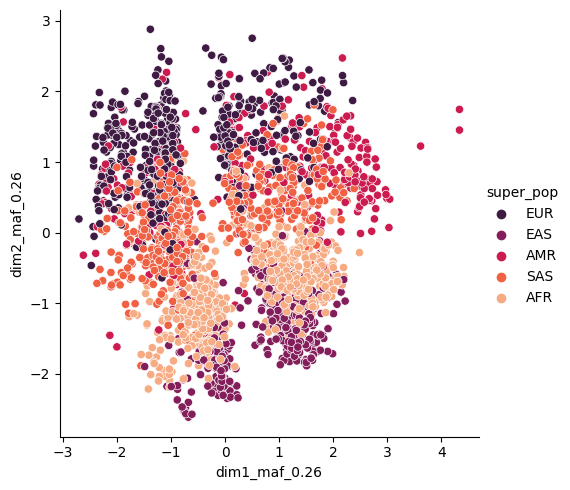

In [13]:
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{maf_pop}", y=f"dim2_maf_{maf_pop}",
    hue="super_pop",
    palette='rocket', sizes=(10, 200))
plt.show()

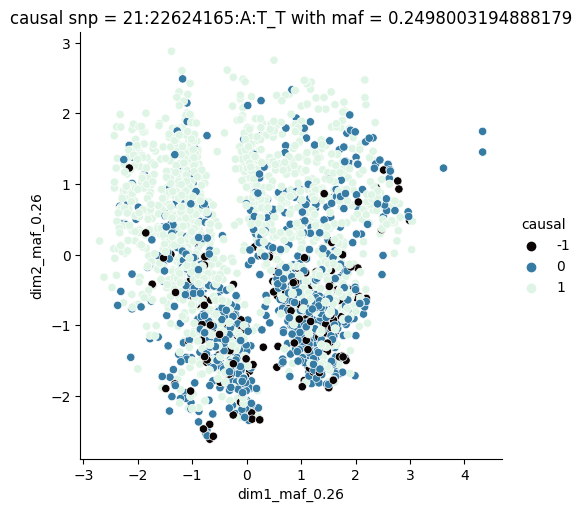

In [14]:
humans[f"causal"] = geno[geno.columns[snp_num]]
g = sns.relplot(
    data=humans,
    x=f"dim1_maf_{maf_pop}", y=f"dim2_maf_{maf_pop}",
    hue=f"causal",
    palette='mako', sizes=(10, 200)).set(title=f"causal snp = {geno.columns[snp_num]} with maf = {maf}")
plt.show()

In [15]:
humans[f"dim1_maf_{maf_pop}"]

0      -0.879453
1      -1.363138
2      -1.326283
3      -1.241521
4      -1.560125
          ...   
2499   -0.889285
2500   -1.007034
2501   -1.510441
2502    0.320206
2503   -1.231021
Name: dim1_maf_0.26, Length: 2504, dtype: float32

In [16]:
humans

,sample,sample.1,pop,super_pop,gender,dim1_maf_0.01,dim2_maf_0.01,pheno_maf_0.01,dim1_maf_0.016,dim2_maf_0.016,...,dim1_maf_0.26,dim2_maf_0.26,pheno_maf_0.26,dim1_maf_0.32,dim2_maf_0.32,pheno_maf_0.32,dim1_maf_0.38,dim2_maf_0.38,pheno_maf_0.38,causal
0,HG00096,HG00096,GBR,EUR,male,-0.333826,-0.040902,-0.374728,-0.170137,0.114625,...,-0.879453,1.282492,0.403039,0.005314,-1.365042,-1.359728,-2.523331,-0.534239,-3.057570,1
1,HG00097,HG00097,GBR,EUR,female,-0.415651,-0.027549,-0.443200,-0.182051,0.113901,...,-1.363138,1.174391,-0.188747,-1.048391,0.857509,-0.190882,-1.793135,1.539269,-0.253866,1
2,HG00099,HG00099,GBR,EUR,female,-0.208906,-0.561815,-0.770721,-0.062809,0.011896,...,-1.326283,0.718506,-0.607776,0.105404,-0.707601,-0.602197,-1.047255,0.997079,-0.050176,1
3,HG00100,HG00100,GBR,EUR,female,-0.252399,-0.179090,-0.431489,-0.352193,0.391056,...,-1.241521,2.305245,1.063723,-0.094720,-0.922529,-1.017250,-1.659191,-0.515448,-2.174640,1
4,HG00101,HG00101,GBR,EUR,male,-0.448655,-0.002134,-0.450789,-0.171656,0.152426,...,-1.560125,0.713983,-0.846141,-0.390248,0.535851,0.145603,-1.882176,-0.099793,-1.981969,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2499,NA21137,NA21137,GIH,SAS,female,-1.082979,1.045842,-0.037137,0.180841,-0.201204,...,-0.889285,-0.411141,-1.300425,0.296090,0.055315,0.351405,0.726802,0.319602,1.046404,1
2500,NA21141,NA21141,GIH,SAS,female,-0.478558,-0.097333,-0.575891,-1.676712,-1.230873,...,-1.007034,0.322640,-0.684395,-0.120413,1.532824,1.412411,-0.964915,-0.019550,-0.984465,1
2501,NA21142,NA21142,GIH,SAS,female,-0.469718,-0.023920,-0.493638,0.045935,-0.116257,...,-1.510441,-0.232557,-1.742997,-0.128187,0.892212,0.764024,-0.438693,0.429210,-0.009483,0
2502,NA21143,NA21143,GIH,SAS,female,-0.511315,0.026747,-0.484568,-0.006030,-0.297905,...,0.320206,0.182804,0.503010,0.305187,-0.068775,0.236412,0.710679,0.701122,1.411802,1


In [18]:
humans_maj = humans[humans['causal']== 1]
humans_het = humans[humans['causal']== 0]
humans_min = humans[humans['causal']== -1]
#df.loc[['viper', 'sidewinder'], ['shield']] = 50

In [19]:
y1_maj + y1_het + y1_min

NameError: name 'y1_maj' is not defined

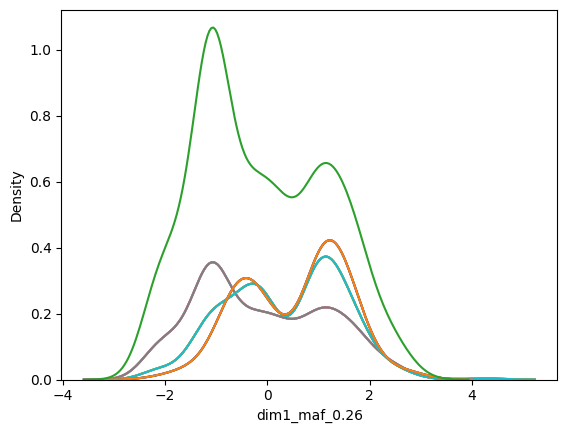

In [21]:
#X1_tot = sns.kdeplot(data=humans, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[0]
#y1_tot = sns.kdeplot(data=humans, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[1]
X1_maj = sns.kdeplot(data=humans_maj, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[0]
y1_maj = sns.kdeplot(data=humans_maj, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[1]
X1_het = sns.kdeplot(data=humans_het, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[0]
y1_het = sns.kdeplot(data=humans_het, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[1]
X1_min = sns.kdeplot(data=humans_min, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[0]
y1_min = sns.kdeplot(data=humans_min, x=f"dim1_maf_{maf_pop}").lines[0].get_data()[1]
sns.lineplot(x=X1_maj, y=y1_maj + y1_het + y1_min)
plt.show()

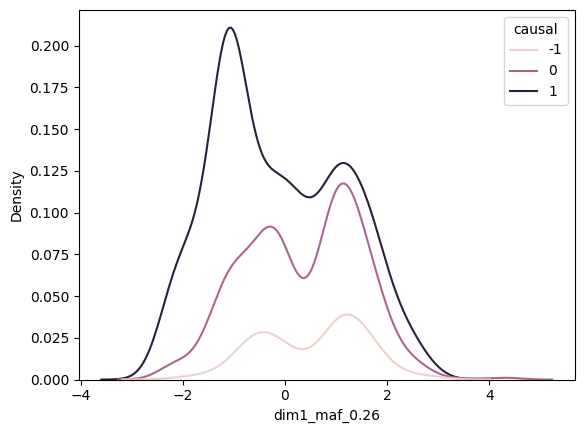

In [22]:
sns.kdeplot(data=humans, x=f"dim1_maf_{maf_pop}", hue="causal")
plt.show()

In [ ]:
sns.kdeplot(data=humans, x=f"dim2_maf_{maf_pop}", hue="causal")
plt.show()

## Nul no strat

In [154]:
estimated_effect_nul = []
estimated_intercept_nul = []
SE_nul = []
p_nul = []

i = 0
for i in range(iteration):
    mean_min = true_mean
    mean_het = true_mean
    mean_maj = true_mean
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno_null']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_nul.append(reg.coef_[0][0])
    estimated_intercept_nul.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_null'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    

    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    
    SE_nul.append(sd_b[1])
    p_nul.append(p_values[1])

## Alt no strat

In [155]:
estimated_effect_alt = []
estimated_intercept_alt = []
SE_alt = []
p_alt = []

for i in range(iteration):
    mean_min = true_mean - true_effect
    mean_het = true_mean
    mean_maj = true_mean + true_effect
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

    X = df_pheno[['geno']]
    y = df_pheno[['pheno']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_alt.append(reg.coef_[0][0])
    estimated_intercept_alt.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    SE_alt.append(sd_b[1])
    p_alt.append(p_values[1])

## Nul strat

In [156]:
estimated_effect_nul_strat = []
estimated_intercept_nul_strat = []
SE_nul_strat = []
p_nul_strat = []

i = 0
for i in range(iteration):
    mean_min = true_mean
    mean_het = true_mean
    mean_maj = true_mean
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno_null": pheno})

    X = df_pheno[['geno']]
    df_pheno['pheno_null_strat'] = df_pheno['pheno_null'] + pheno_pop
    y = df_pheno[['pheno_null_strat']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_nul_strat.append(reg.coef_[0][0])
    estimated_intercept_nul_strat.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_null_strat'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    

    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    
    SE_nul_strat.append(sd_b[1])
    p_nul_strat.append(p_values[1])

## Alt strat

In [157]:
estimated_effect_alt_strat = []
estimated_intercept_alt_strat = []
SE_alt_strat = []
p_alt_strat = []

for i in range(iteration):
    mean_min = true_mean - true_effect
    mean_het = true_mean
    mean_maj = true_mean + true_effect
    sigma_min = true_sd
    sigma_het = true_sd
    sigma_maj = true_sd
    pheno = []
    for var in list(geno[geno.columns[snp_num]]):
        if var == 1:
            pheno.append(np.random.normal(mean_maj, sigma_maj, 1)[0])
        elif var == 0:
            pheno.append(np.random.normal(mean_het, sigma_het, 1)[0])
        else:
            pheno.append(np.random.normal(mean_min, sigma_min, 1)[0])
    df_pheno = pd.DataFrame(data = {"geno": list(geno[geno.columns[snp_num]]), "pheno": pheno})

    X = df_pheno[['geno']]
    df_pheno['pheno_alt_strat'] = df_pheno['pheno'] + pheno_pop
    y = df_pheno[['pheno_alt_strat']]
    reg = LinearRegression().fit(X, y)
    estimated_effect_alt_strat.append(reg.coef_[0][0])
    estimated_intercept_alt_strat.append(reg.intercept_[0])
    
    # Calculating p values and standard error
    N = len(X)
    p = len(X.columns) + 1
    X_with_intercept = np.empty(shape=(N, p), dtype=float)
    X_with_intercept[:, 0] = 1
    X_with_intercept[:, 1:p] = X.values
    
    params = np.append(reg.intercept_,reg.coef_)
    predictions = reg.predict(X)
    new_y = (y-predictions)**2
    newX = pd.DataFrame({"Constant":np.ones(len(X))}).join(pd.DataFrame(list(X['geno'])))
    MSE = (sum(list(new_y['pheno_alt_strat'])))/(len(newX)-len(newX.columns))
    
    var_b = MSE*(np.linalg.inv(np.dot(newX.T,newX)).diagonal())
    sd_b = np.sqrt(var_b)
    ts_b = params/ sd_b
    
    p_values =[2*(1-stats.t.cdf(np.abs(i),(len(newX)-len(newX.columns)))) for i in ts_b]
    SE_alt_strat.append(sd_b[1])
    p_alt_strat.append(p_values[1])

In [158]:
labels = ['nul hypothesis'] * len(estimated_effect_nul) + ['alternate hypothesis'] * len(estimated_effect_alt) + ['nul hypothesis stratified'] * len(estimated_effect_nul_strat)+ ['alternate hypothesis stratified'] * len(estimated_effect_alt_strat) 
dis = pd.DataFrame(data={"Z": list(estimated_effect_nul)+ list(estimated_effect_alt)+ list(estimated_effect_nul_strat)+ list(estimated_effect_alt_strat), 'labels': labels})

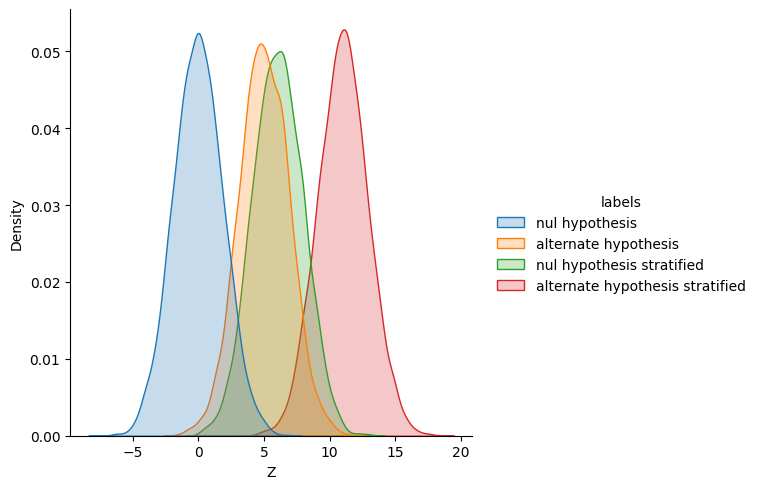

In [159]:
sns_plot = sns.displot(dis, x="Z", hue='labels',kind="kde",fill=True)
plt.show()